# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Raihan Nurhakim | 5054251030 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [ ]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv("data.csv")
df.columns = df.columns.str.strip()

print("shape:", df.shape)
print("\ntipe data:")
print(df.dtypes.value_counts())
print("\nmissing values per kolom:", df.isnull().sum().sum())
print("\nstatistik deskriptif:")
df.describe()

shape: (569, 33)

tipe data:
float64    31
int64       1
object      1
Name: count, dtype: int64

missing values per kolom: 569

statistik deskriptif:


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


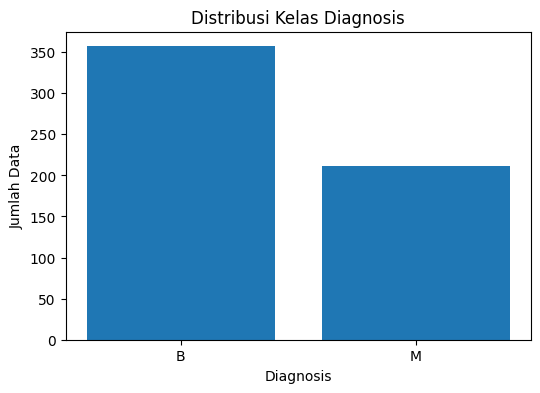

diagnosis
B    357
M    212
Name: count, dtype: int64
Proporsi kelas (%):
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


In [3]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
counts = df['diagnosis'].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values)
plt.title('Distribusi Kelas Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Jumlah Data')
plt.show()

print(counts)
print('Proporsi kelas (%):')
print((df['diagnosis'].value_counts(normalize=True) * 100).round(2))


C:\Users\Raihan\AppData\Local\Temp\ipykernel_28456\592158711.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=['B', 'M'])
C:\Users\Raihan\AppData\Local\Temp\ipykernel_28456\592158711.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=['B', 'M'])
C:\Users\Raihan\AppData\Local\Temp\ipykernel_28456\592158711.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=['B', 'M'])
C:\Users\Raihan\AppData\Local\Temp\ipykernel_28456\592158711.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Ma

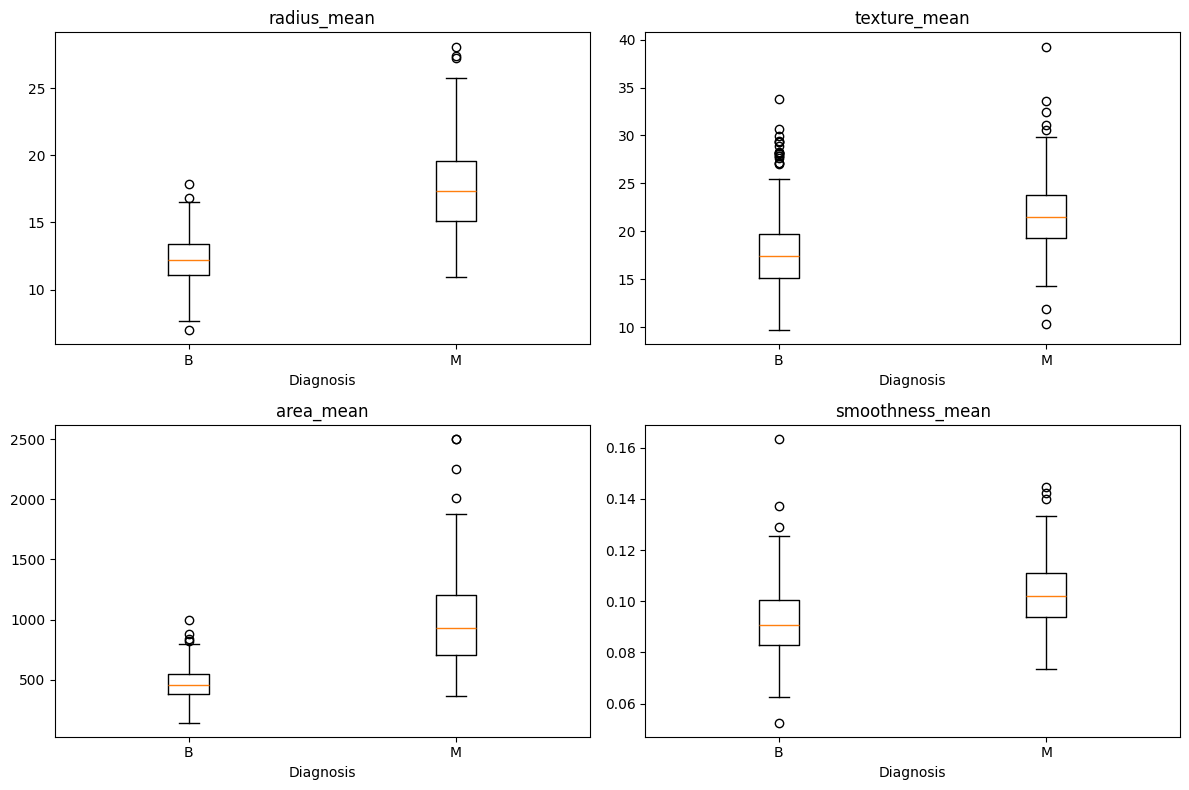

In [4]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas (linear) antar kelas, atau justru tumpang tindih.
selected_features = ['radius_mean', 'texture_mean', 'area_mean', 'smoothness_mean']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(selected_features, axes.flatten()):
    values = [df.loc[df['diagnosis'] == label, feature] for label in ['B', 'M']]
    ax.boxplot(values, labels=['B', 'M'])
    ax.set_title(feature)
    ax.set_xlabel('Diagnosis')
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [5]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
df = df.drop(columns=['Unnamed: 32', 'id'], errors='ignore')
print('Missing value sebelum penanganan:', df.isnull().sum().sum())


Missing value sebelum penanganan: 0


In [6]:
print(df.dtypes.value_counts())

float64    30
object      1
Name: count, dtype: int64


In [7]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).

In [ ]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = df.drop(columns=['diagnosis'])
y = df['diagnosis'].map({'B': 0, 'M': 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('Distribusi train:\n', y_train.value_counts(normalize=True).round(3))
print('Distribusi test:\n', y_test.value_counts(normalize=True).round(3))


X_train: (455, 30)
X_test : (114, 30)
Distribusi train:
 diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64
Distribusi test:
 diagnosis
0    0.632
1    0.368
Name: proportion, dtype: float64


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [9]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [10]:
# Inisialisasi dan latih model SVC dengan kernel='linear' menggunakan train set (yang sudah discaling).
linear_model = SVC(kernel='linear', C=1)
linear_model.fit(X_train_scaled, y_train)


SVC(C=1, kernel='linear')

In [11]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_linear = linear_model.predict(X_test_scaled)


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [12]:
# Inisialisasi dan latih model SVC dengan kernel='rbf' menggunakan train set.
# Gunakan nilai hyperparameter lain (C) yang sama seperti model Linear di atas, agar perbandingan adil.
rbf_model = SVC(kernel='rbf', C=1, gamma='scale')
rbf_model.fit(X_train_scaled, y_train)


SVC(C=1)

In [13]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_rbf = rbf_model.predict(X_test_scaled)


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [14]:
# Latih beberapa model SVC (kernel RBF) dengan variasi nilai C,
# misalnya 0.01, 0.1, 1, 10, 100.
# Gunakan gamma='scale' atau nilai gamma tetap agar perbandingan fokus pada pengaruh C.
C_values = [0.01, 0.1, 1, 10, 100]
models_C = {}
for c in C_values:
    model = SVC(kernel='rbf', C=c, gamma='scale')
    model.fit(X_train_scaled, y_train)
    models_C[c] = model


In [15]:
# Hitung akurasi pada train set dan test set untuk setiap nilai C yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
train_accuracies = []
test_accuracies = []
for c in C_values:
    model = models_C[c]
    train_accuracies.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_accuracies.append(accuracy_score(y_test, model.predict(X_test_scaled)))

results_C = pd.DataFrame({
    'C': C_values,
    'Akurasi Train': train_accuracies,
    'Akurasi Test': test_accuracies
})
results_C


,C,Akurasi Train,Akurasi Test
0,0.01,0.626374,0.631579
1,0.10,0.953846,0.947368
2,1.00,0.986813,0.973684
3,10.00,0.989011,0.973684
4,100.00,1.000000,0.964912


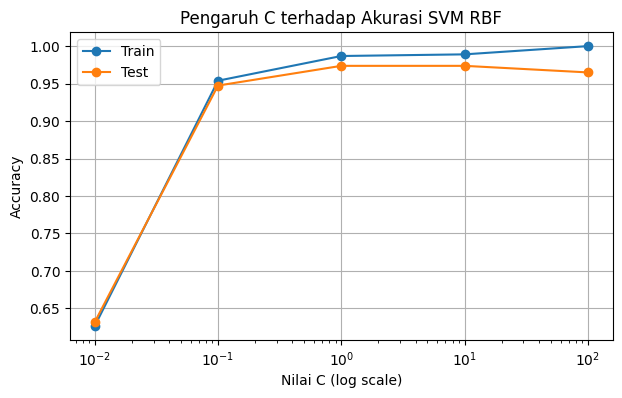

In [16]:
# Plot grafik akurasi training vs testing terhadap nilai C (gunakan sumbu x logaritmik) dalam satu chart.
# Amati pada nilai C berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
plt.figure(figsize=(7, 4))
plt.plot(C_values, train_accuracies, marker='o', label='Train')
plt.plot(C_values, test_accuracies, marker='o', label='Test')
plt.xscale('log')
plt.xlabel('Nilai C (log scale)')
plt.ylabel('Accuracy')
plt.title('Pengaruh C terhadap Akurasi SVM RBF')
plt.legend()
plt.grid(True)
plt.show()


# 4. Evaluasi Model

In [17]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model kernel Linear dan RBF.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
metrics = []
for name, y_pred in [('Linear', y_pred_linear), ('RBF', y_pred_rbf)]:
    metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

metrics_df = pd.DataFrame(metrics).set_index('Model')
metrics_df


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Linear,0.964912,1.0,0.904762,0.950000
RBF,0.973684,1.0,0.928571,0.962963


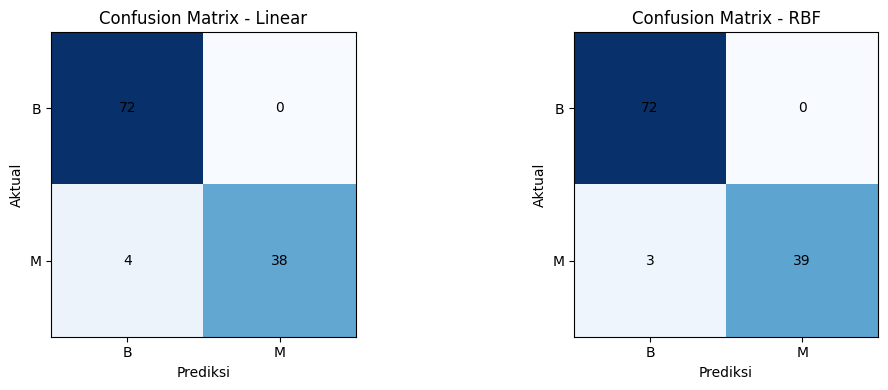

In [18]:
# Tampilkan Confusion Matrix untuk model kernel Linear dan RBF dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, y_pred in zip(axes, ['Linear', 'RBF'], [y_pred_linear, y_pred_rbf]):
    cm = confusion_matrix(y_test, y_pred)
    ax.imshow(cm, cmap='Blues')
    ax.set_title(f'Confusion Matrix - {name}')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    ax.set_xticks([0, 1], labels=['B', 'M'])
    ax.set_yticks([0, 1], labels=['B', 'M'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout()
plt.show()


In [19]:
# Tampilkan jumlah support vectors dari model dengan performa terbaik (atribut model.support_vectors_ atau model.n_support_).
# Bandingkan jumlah support vectors antara model Linear dan RBF.
best_model_name = metrics_df['F1-Score'].idxmax()
best_model = linear_model if best_model_name == 'Linear' else rbf_model
print('Model dengan F1-Score tertinggi:', best_model_name)
print('Support vectors per kelas (Linear):', linear_model.n_support_)
print('Total support vectors (Linear):', len(linear_model.support_vectors_))
print('Support vectors per kelas (RBF):', rbf_model.n_support_)
print('Total support vectors (RBF):', len(rbf_model.support_vectors_))


Model dengan F1-Score tertinggi: RBF
Support vectors per kelas (Linear): [19 19]
Total support vectors (Linear): 38
Support vectors per kelas (RBF): [50 57]
Total support vectors (RBF): 107


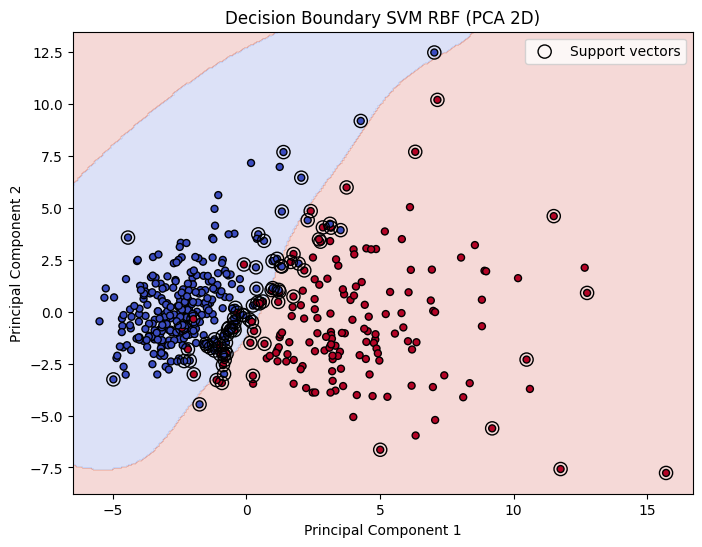

Variansi yang dijelaskan PCA: 0.631


In [20]:
# Jika memungkinkan, pilih dua fitur (atau reduksi dimensi dengan PCA ke 2D) lalu visualisasikan decision boundary
# beserta margin dan support vectors dari model terbaik.
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
pca_model = SVC(kernel=best_model.kernel, C=best_model.C, gamma=best_model.gamma)
pca_model.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = pca_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.2, cmap='coolwarm')
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', s=25)
plt.scatter(X_train_pca[pca_model.support_, 0], X_train_pca[pca_model.support_, 1],
            facecolors='none', edgecolors='black', s=90, label='Support vectors')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'Decision Boundary SVM {best_model_name} (PCA 2D)')
plt.legend()
plt.show()
print('Variansi yang dijelaskan PCA:', pca.explained_variance_ratio_.sum().round(3))


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa SVM dengan kernel Linear vs RBF. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian, dikaitkan dengan bentuk sebaran data pada EDA?
- Jelaskan temuan dari eksperimen regularisasi (nilai `C`). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Bandingkan jumlah support vectors antara model Linear dan RBF. Apa hubungan jumlah support vectors dengan kompleksitas batas keputusan yang terbentuk?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

Berdasarkan hasil evaluasi, kernel RBF memperoleh accuracy 0,9737 dan F1-Score 0,9630, sedikit lebih tinggi dibandingkan kernel Linear dengan accuracy 0,9649 dan F1-Score 0,9500. Precision kedua model mencapai 1,00, sedangkan recall RBF (0,9286) lebih tinggi daripada Linear (0,9048). Hasil ini menunjukkan bahwa RBF sedikit lebih baik dalam mengenali kelas positif pada pembagian data ini.

Pada eksperimen nilai C, akurasi test meningkat dari 0,6316 (C=0,01) menjadi 0,9737 (C=1 dan C=10). Pada C=100, akurasi training mencapai 1,00, tetapi akurasi test turun menjadi 0,9649. Pola tersebut menunjukkan gejala overfitting mulai terlihat pada C=100 karena performa training terus meningkat sementara performa test menurun.

Jumlah support vectors pada model Linear adalah 38, sedangkan pada RBF adalah 107. Pada eksperimen ini, RBF menggunakan lebih banyak support vectors untuk membentuk batas keputusan non-linear. Jumlah tersebut menunjukkan banyaknya titik data yang berperan dalam menentukan batas keputusan, tetapi tidak menjadi satu-satunya ukuran kompleksitas model.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba kernel Polynomial, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Pada dataset ini, kernel RBF menghasilkan accuracy dan F1-Score sedikit lebih tinggi dibandingkan kernel Linear. Eksperimen parameter C menunjukkan bahwa C=1 dan C=10 memberikan akurasi test tertinggi, sedangkan C=100 mulai menunjukkan gejala overfitting. Model RBF memiliki jumlah support vectors lebih banyak daripada model Linear.

Untuk eksperimen selanjutnya, dapat dicoba variasi nilai gamma atau GridSearchCV untuk mencari kombinasi hyperparameter yang sesuai.